# Groundwater temporal exploratory analysis

This notebook continues the questions in Charlsey's original exploratory work using the reviewed cleaned nitrate table. It groups records by well ID, keeps all observations, and does not write datasets.

In [ ]:
from pathlib import Path

# Run this notebook from the repository root.
DATA_PATH = Path('notebooks/groundwater/groundwater_nitrate_clean.csv')

# Groundwater nitrate: reviewed exploratory analysis

The analyses use the existing cleaned CSV. They keep all concentrations and observations, use well IDs to identify wells, and leave shared coordinates as a separate question. The CSV's analyte label is retained; analyte equivalence and nitrogen units still need scientific review.

## Load the existing nitrate table

Each row is an existing cleaned sample. Well IDs are read as text to preserve their formatting, and the sample year is derived for summaries. This notebook does not rerun cleaning or write datasets.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

groundwater = pd.read_csv(
    DATA_PATH,
    dtype={"gm_well_id": "string", "src_samp_collection_time": "string"}
)
groundwater["gm_samp_collection_date"] = pd.to_datetime(
    groundwater["gm_samp_collection_date"]
)
groundwater["year"] = groundwater["gm_samp_collection_date"].dt.year
print(f"Observations: {len(groundwater):,}")
print(f"Unique well IDs: {groundwater['gm_well_id'].nunique():,}")
display(groundwater.isna().sum().rename("missing_values"))
display(groundwater["nitrate_mg_L"].describe())


Observations: 10,665
Unique well IDs: 3,245


gm_well_id                  0
gm_well_category            0
gm_samp_collection_date     0
src_samp_collection_time    0
gm_latitude                 0
gm_longitude                0
nitrate_mg_L                0
year                        0
Name: missing_values, dtype: int64

count    10665.000000
mean        13.123557
std         21.049301
min          0.000000
25%          1.500000
50%          4.200000
75%         15.500000
max        230.000000
Name: nitrate_mg_L, dtype: float64

## Shared coordinates

Different well IDs can have the same recorded coordinates. The next check counts these overlaps without merging IDs; coordinates alone cannot confirm that records represent the same physical well.

## Well identifiers and shared coordinates

This diagnostic reports shared positions only. It does not treat wells within 30 m, or with identical coordinates, as duplicates.

In [2]:
well_locations = groundwater[
    ["gm_well_id", "gm_latitude", "gm_longitude"]
].drop_duplicates()
coordinate_counts = well_locations.groupby(
    ["gm_latitude", "gm_longitude"]
)["gm_well_id"].nunique().reset_index(name="well_count")
shared_coordinates = coordinate_counts[coordinate_counts["well_count"] > 1]
shared_wells = well_locations.merge(
    shared_coordinates, on=["gm_latitude", "gm_longitude"], how="inner"
)
print(f"Coordinate pairs shared by multiple IDs: {len(shared_coordinates)}")
display(shared_wells.sort_values(["gm_latitude", "gm_longitude", "gm_well_id"]))
display(well_locations.groupby("gm_well_id").size().value_counts().rename("well_count"))


Coordinate pairs shared by multiple IDs: 50


,gm_well_id,gm_latitude,gm_longitude,well_count
92,AGL020038261-WH DW,35.529884,-120.672465,2
95,AGL020039146-WH DW,35.529884,-120.672465,2
78,AGL020012842-AG WELL,35.572894,-120.712583,2
96,AGL020039326-AG WELL,35.572894,-120.712583,2
87,AGL020027467-BLACKSETH DW,35.582080,-120.708688,2
...,...,...,...,...
35,AGL020000974-CCGC_0031,36.676600,-121.699750,2
31,AGC100000001-CCGC_0548,36.678370,-121.722960,2
67,AGL020004641-CCGC_0548,36.678370,-121.722960,2
16,AGC100000001-CCGC_0070,36.686000,-121.734450,2


1    3245
Name: well_count, dtype: int64

## Flag unusual values for review

The global threshold is Q3 + 1.5 times the interquartile range; negative values are also flagged. These are review flags, not proof of errors or a health standard. No observations are removed, and wells sampled more often contribute more records to this threshold.

## Global IQR flags

The threshold is calculated across all observations. High nitrate values remain in the data, and the flags are not a model preprocessing rule.

Upper review threshold: 36.500
Flagged observations: 1,148


,gm_well_id,gm_well_category,gm_samp_collection_date,src_samp_collection_time,gm_latitude,gm_longitude,nitrate_mg_L,year,is_outlier
7675,AGL020015946-WELL 1,Irrigation / Industrial,2018-08-15,1400,35.637749,-120.856456,230.00,2018,True
4337,AGL020004057-HOME_DOM,Domestic,2025-05-20,0906,36.638430,-121.563200,229.00,2025,True
4336,AGL020004057-HOME_DOM,Domestic,2024-05-03,1027,36.638430,-121.563200,227.00,2024,True
4334,AGL020004057-HOME_DOM,Domestic,2022-04-06,1305,36.638430,-121.563200,214.00,2022,True
6477,AGL020008662-WELL #3,Domestic,2017-04-20,1400,36.617980,-121.558400,204.00,2017,True
...,...,...,...,...,...,...,...,...,...
464,AGL020000623-GLAU1IRR,Irrigation / Industrial,2024-05-24,1005,36.008080,-120.885800,36.70,2024,True
144,AGC100000001-CCGC_0206,Domestic,2014-03-19,1330,36.387130,-121.355830,36.60,2014,True
413,AGL020000601-SWRI,Irrigation / Industrial,2024-05-24,1115,36.184650,-121.068450,36.60,2024,True
3468,AGL020003492-PUMP 1 GIACOMAZ,Domestic,2025-05-20,0815,36.333000,-121.221910,36.60,2025,True


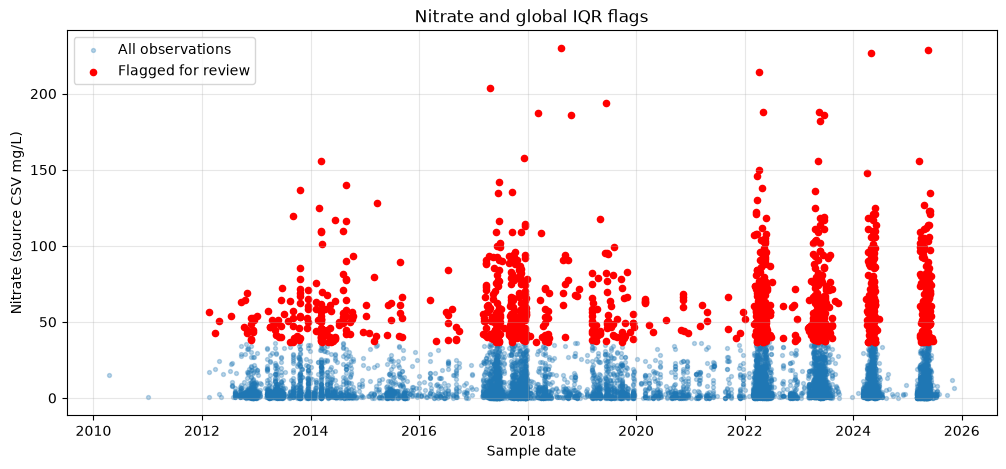

In [3]:
q1 = groundwater["nitrate_mg_L"].quantile(0.25)
q3 = groundwater["nitrate_mg_L"].quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)
groundwater["is_outlier"] = (
    (groundwater["nitrate_mg_L"] < 0)
    | (groundwater["nitrate_mg_L"] > upper)
)
print(f"Upper review threshold: {upper:.3f}")
print(f"Flagged observations: {groundwater['is_outlier'].sum():,}")
display(groundwater.loc[groundwater["is_outlier"]].sort_values(
    "nitrate_mg_L", ascending=False
))

flagged = groundwater[groundwater["is_outlier"]]
fig, ax = plt.subplots(figsize=(12, 5))
ax.scatter(groundwater["gm_samp_collection_date"], groundwater["nitrate_mg_L"],
           s=8, alpha=0.3, label="All observations")
ax.scatter(flagged["gm_samp_collection_date"], flagged["nitrate_mg_L"],
           s=20, color="red", label="Flagged for review")
ax.set(xlabel="Sample date", ylabel="Nitrate (source CSV mg/L)", title="Nitrate and global IQR flags")
ax.legend()
ax.grid(alpha=0.3)
plt.show()


## Compare well summaries with flagged values

The next table is a sensitivity check. It keeps the original concentrations; if a well has no unflagged observations, its unflagged mean is missing.

## Sensitivity to flagged observations

For each well ID, compare its mean and median with the mean of its unflagged observations. The unflagged mean is only a comparison; it does not replace data or exclude a well. Large differences may be worth investigating.

In [4]:
comparison = groundwater.groupby("gm_well_id").agg(
    mean_all=("nitrate_mg_L", "mean"), median_all=("nitrate_mg_L", "median"),
    observations=("nitrate_mg_L", "size"), flagged_count=("is_outlier", "sum")
)
comparison["mean_unflagged"] = groundwater.loc[
    ~groundwater["is_outlier"]
].groupby("gm_well_id")["nitrate_mg_L"].mean()
display(comparison.loc[comparison["flagged_count"] > 0])


,mean_all,median_all,observations,flagged_count,mean_unflagged
gm_well_id,,,,,
AGC100000001-CCGC_0003,66.85,66.85,1,1,NaN
AGC100000001-CCGC_0006,53.55,53.55,1,1,NaN
AGC100000001-CCGC_0008,62.75,62.75,1,1,NaN
AGC100000001-CCGC_0015,54.00,54.00,1,1,NaN
AGC100000001-CCGC_0017,137.00,137.00,1,1,NaN
...,...,...,...,...,...
AGL020040221-WELL 1,44.05,44.05,2,2,NaN
AGL020040688-MUSANTE 17,56.10,56.10,1,1,NaN
AGL020040869-AG WELL,96.60,96.60,1,1,NaN


## Sampling coverage and within-well variability

Observation counts and distinct sample dates answer different questions. A range is maximum minus minimum, not a variance or trend test; a zero range from one observation does not show stability.

## Temporal coverage by well

Several measurements on one date still represent one sampling date. Ranges can be affected by sampling intensity and individual high values. The yearly table shows which wells contribute data in each calendar year.

,observations,sample_dates,first_date,last_date,median,mean,minimum,maximum,std,range
gm_well_id,,,,,,,,,,
AGC100000001-CCGC_0001,1,1,2013-10-24,2013-10-24,4.70,4.70,4.70,4.70,NaN,0.0
AGC100000001-CCGC_0002,1,1,2013-10-24,2013-10-24,21.90,21.90,21.90,21.90,NaN,0.0
AGC100000001-CCGC_0003,1,1,2013-10-24,2013-10-24,66.85,66.85,66.85,66.85,NaN,0.0
AGC100000001-CCGC_0005,1,1,2013-10-21,2013-10-21,7.25,7.25,7.25,7.25,NaN,0.0
AGC100000001-CCGC_0006,1,1,2013-10-25,2013-10-25,53.55,53.55,53.55,53.55,NaN,0.0
...,...,...,...,...,...,...,...,...,...,...
AGL020040966-DUAL,1,1,2025-07-15,2025-07-15,4.30,4.30,4.30,4.30,NaN,0.0
AGL020040967-AW5504,1,1,2025-07-10,2025-07-10,4.10,4.10,4.10,4.10,NaN,0.0
AGL020040968-WELL 2,1,1,2025-07-10,2025-07-10,2.60,2.60,2.60,2.60,NaN,0.0


,observations,sample_dates,range
count,3245.000000,3245.000000,3245.000000
mean,3.286595,3.282897,5.133569
std,2.711092,2.709206,11.029354
min,1.000000,1.000000,0.000000
25%,1.000000,1.000000,0.000000
50%,3.000000,3.000000,0.800000
75%,4.000000,4.000000,4.500000
max,30.000000,30.000000,154.900000


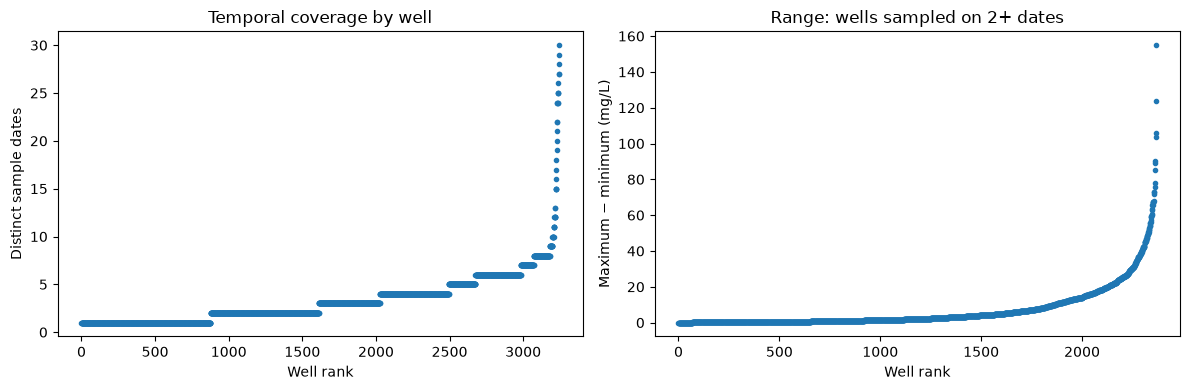

,observations,wells,percent_of_all_wells
year,,,
2010,1,1,0.030817
2011,1,1,0.030817
2012,382,368,11.340524
2013,708,653,20.123267
2014,457,391,12.049307
2015,267,209,6.440678
2016,130,110,3.389831
2017,2147,1442,44.437596
2018,349,308,9.491525


In [5]:
well_summary = groundwater.groupby("gm_well_id").agg(
    observations=("nitrate_mg_L", "size"),
    sample_dates=("gm_samp_collection_date", "nunique"),
    first_date=("gm_samp_collection_date", "min"),
    last_date=("gm_samp_collection_date", "max"),
    median=("nitrate_mg_L", "median"), mean=("nitrate_mg_L", "mean"),
    minimum=("nitrate_mg_L", "min"), maximum=("nitrate_mg_L", "max"),
    std=("nitrate_mg_L", "std")
)
well_summary["range"] = well_summary["maximum"] - well_summary["minimum"]
display(well_summary)
display(well_summary[["observations", "sample_dates", "range"]].describe())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(well_summary["sample_dates"].sort_values().to_numpy(), ".")
axes[0].set(xlabel="Well rank", ylabel="Distinct sample dates", title="Temporal coverage by well")
repeated = well_summary[well_summary["sample_dates"] >= 2]
axes[1].plot(repeated["range"].sort_values().to_numpy(), ".")
axes[1].set(xlabel="Well rank", ylabel="Maximum âˆ’ minimum (mg/L)", title="Range: wells sampled on 2+ dates")
plt.tight_layout()
plt.show()

yearly_coverage = groundwater.groupby("year").agg(
    observations=("gm_well_id", "size"), wells=("gm_well_id", "nunique")
)
yearly_coverage["percent_of_all_wells"] = (
    100 * yearly_coverage["wells"] / groundwater["gm_well_id"].nunique()
)
display(yearly_coverage)


## Annual summaries, 2022 to 2025

The same summaries are calculated for each year. A range above 10 mg/L is retained as a review flag only; no well or observation is excluded.

## Annual coverage and repeated measurements

Within each well ID and year, the table reports observation counts, distinct dates, central values, and ranges. One measurement cannot show within-year change, and uneven sampling limits year-to-year comparisons.

2022: 1383 wells; 1459 observations; 34 wells sampled on 2+ dates
2023: 1280 wells; 1298 observations; 18 wells sampled on 2+ dates
2024: 1245 wells; 1252 observations; 7 wells sampled on 2+ dates
2025: 1276 wells; 1277 observations; 1 wells sampled on 2+ dates


,observations,sample_dates,range
count,1383.000000,1383.000000,1383.000000
mean,1.054953,1.054230,0.155345
std,0.402438,0.401636,1.919639
min,1.000000,1.000000,0.000000
25%,1.000000,1.000000,0.000000
50%,1.000000,1.000000,0.000000
75%,1.000000,1.000000,0.000000
max,6.000000,6.000000,49.900000


,gm_well_id,year,observations,sample_dates,mean,median,minimum,maximum,std,range,flag_range_above_10
2450,AGL020007533-GH20-07,2022,5,5,29.770000,31.550,20.00,36.50,7.201180,16.50,True
2456,AGL020007535-GH17-02,2022,6,6,12.366667,3.850,2.20,52.10,19.586798,49.90,True
2469,AGL020007540-GH12-09,2022,5,5,29.980000,28.000,16.80,51.60,12.958617,34.80,True
3141,AGL020014956-GH23-10,2022,4,4,32.175000,33.725,21.80,39.45,8.583366,17.65,True
3285,AGL020017603-GH18-01,2022,3,3,24.983333,20.850,20.75,33.35,7.245918,12.60,True
3287,AGL020017603-GH18-03,2022,3,3,27.000000,25.250,22.15,33.60,5.922204,11.45,True
3288,AGL020017603-GH18-DOM,2022,4,4,16.025000,19.925,3.40,20.85,8.458181,17.45,True


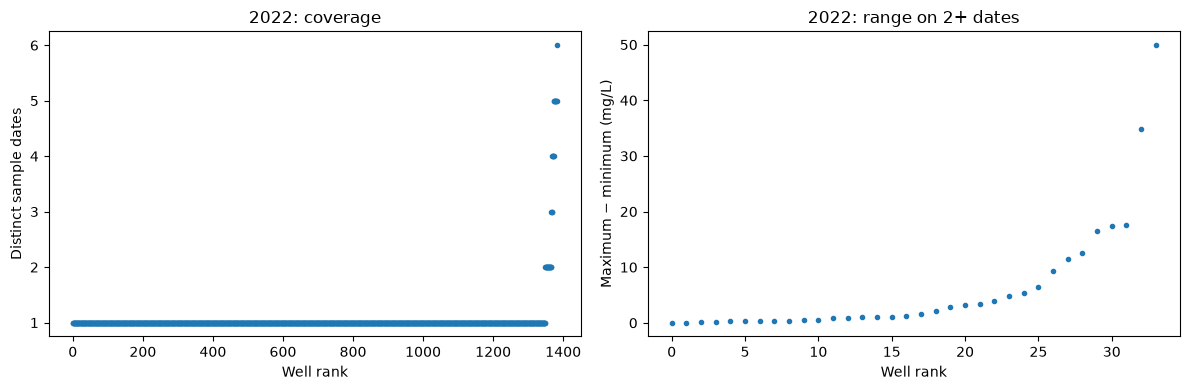

,observations,sample_dates,range
count,1280.000000,1280.000000,1280.000000
mean,1.014063,1.014063,0.063613
std,0.117795,0.117795,1.107603
min,1.000000,1.000000,0.000000
25%,1.000000,1.000000,0.000000
50%,1.000000,1.000000,0.000000
75%,1.000000,1.000000,0.000000
max,2.000000,2.000000,35.300000


,gm_well_id,year,observations,sample_dates,mean,median,minimum,maximum,std,range,flag_range_above_10
2470,AGL020007540-GH12-09,2023,2,2,15.075,15.075,9.25,20.9,8.237794,11.65,True
4315,AGL020037470-GH27-01,2023,2,2,14.700,14.700,8.80,20.6,8.343860,11.80,True
4319,AGL020037470-GH27-DOM,2023,2,2,26.250,26.250,8.60,43.9,24.960869,35.30,True


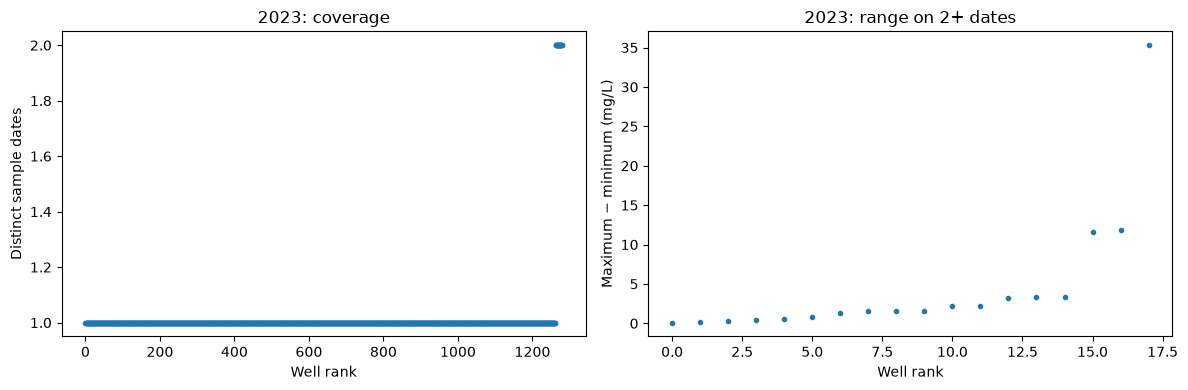

,observations,sample_dates,range
count,1245.000000,1245.000000,1245.000000
mean,1.005622,1.005622,0.044755
std,0.074802,0.074802,1.052825
min,1.000000,1.000000,0.000000
25%,1.000000,1.000000,0.000000
50%,1.000000,1.000000,0.000000
75%,1.000000,1.000000,0.000000
max,2.000000,2.000000,30.700000


,gm_well_id,year,observations,sample_dates,mean,median,minimum,maximum,std,range,flag_range_above_10
188,AGL020000704-BR_AGWELL1,2024,2,2,30.85,30.85,15.5,46.2,21.708178,30.7,True
4815,AGL020039606-MC DOUGALL2,2024,2,2,23.20,23.20,12.8,33.6,14.707821,20.8,True


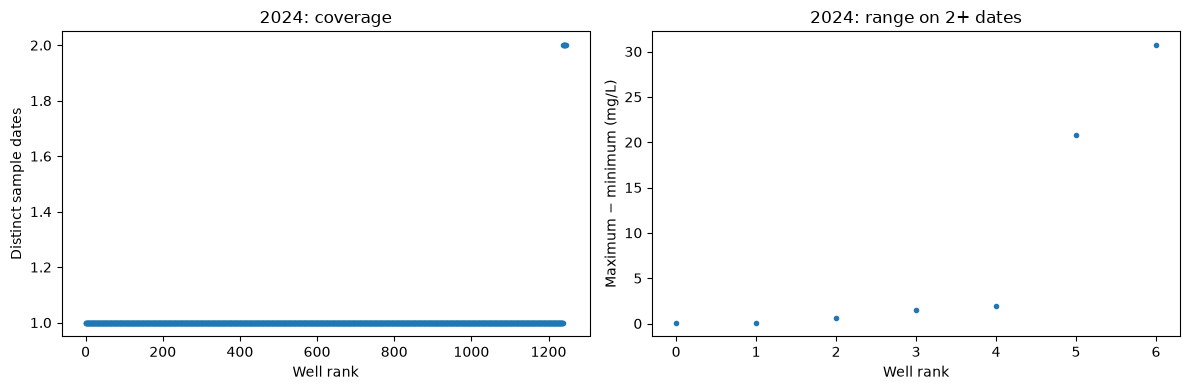

,observations,sample_dates,range
count,1276.000000,1276.000000,1276.000000
mean,1.000784,1.000784,0.000392
std,0.027995,0.027995,0.013997
min,1.000000,1.000000,0.000000
25%,1.000000,1.000000,0.000000
50%,1.000000,1.000000,0.000000
75%,1.000000,1.000000,0.000000
max,2.000000,2.000000,0.500000


,gm_well_id,year,observations,sample_dates,mean,median,minimum,maximum,std,range,flag_range_above_10


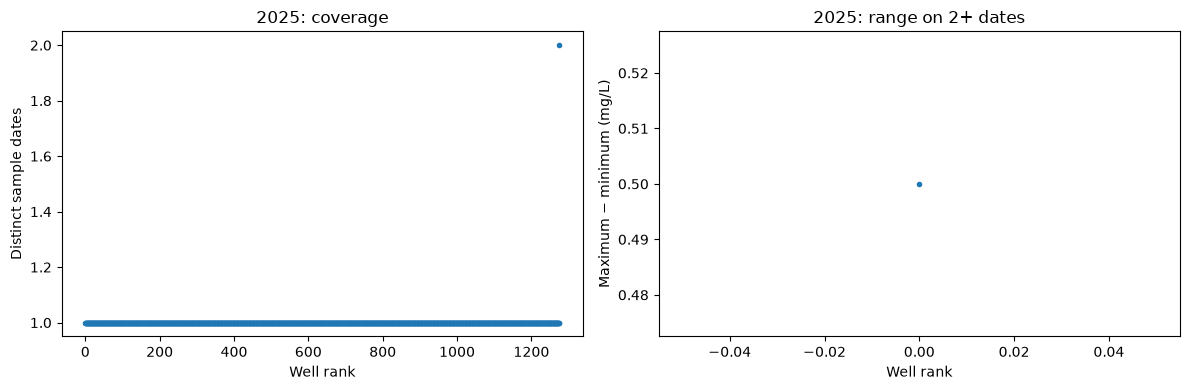

In [6]:
years = [2022, 2023, 2024, 2025]
groundwater_period = groundwater[groundwater["year"].isin(years)].copy()
annual_summary = groundwater_period.groupby(["gm_well_id", "year"]).agg(
    observations=("nitrate_mg_L", "size"),
    sample_dates=("gm_samp_collection_date", "nunique"),
    mean=("nitrate_mg_L", "mean"), median=("nitrate_mg_L", "median"),
    minimum=("nitrate_mg_L", "min"), maximum=("nitrate_mg_L", "max"),
    std=("nitrate_mg_L", "std")
).reset_index()
annual_summary["range"] = annual_summary["maximum"] - annual_summary["minimum"]
annual_summary["flag_range_above_10"] = annual_summary["range"] > 10

for year in years:
    annual = annual_summary[annual_summary["year"] == year]
    print(f"{year}: {len(annual)} wells; {annual['observations'].sum()} observations; "
          f"{(annual['sample_dates'] >= 2).sum()} wells sampled on 2+ dates")
    display(annual[["observations", "sample_dates", "range"]].describe())
    display(annual[annual["flag_range_above_10"]])
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(annual["sample_dates"].sort_values().to_numpy(), ".")
    axes[0].set(xlabel="Well rank", ylabel="Distinct sample dates", title=f"{year}: coverage")
    repeated = annual[annual["sample_dates"] >= 2]
    axes[1].plot(repeated["range"].sort_values().to_numpy(), ".")
    axes[1].set(xlabel="Well rank", ylabel="Maximum âˆ’ minimum (mg/L)", title=f"{year}: range on 2+ dates")
    plt.tight_layout()
    plt.show()


## Well IDs observed in all four years

This matched subset uses the same well IDs for annual means and medians. It may not represent all wells. No IQR or range exclusions are applied.

## Compare annual summaries for matched wells

The 2022 to 2025 period is unchanged. Adjacent-year differences are descriptive, not tests of significance or causal effects. Requiring data in every year selects a subset that may not represent all wells. The total range also includes within-year variation; the diagonal in the first-versus-last-year plot marks equal annual medians.

Well IDs measured in all four years: 738


year,2022,2023,2024,2025
gm_well_id,,,,
AGL020000465-PRIMARY,3.12,2.97,3.38,3.14
AGL020000484-ROOS-HOMESTEAD,3.82,5.14,4.36,3.42
AGL020000518-M-24,95.40,76.60,90.80,89.60
AGL020000519-J-23,42.60,40.10,40.70,37.90
AGL020000519-J-26,17.00,8.70,11.20,11.30
...,...,...,...,...
AGL020039374-HOGUE WELL,2.03,1.80,2.30,2.70
AGL020039380-DOLE 1,2.00,1.40,1.50,1.60
AGL020039399-SOUTH,1.00,3.00,4.90,7.20


year,2022,2023,2024,2025
gm_well_id,,,,
AGL020000465-PRIMARY,3.12,2.97,3.38,3.14
AGL020000484-ROOS-HOMESTEAD,3.82,5.14,4.36,3.42
AGL020000518-M-24,95.40,76.60,90.80,89.60
AGL020000519-J-23,42.60,40.10,40.70,37.90
AGL020000519-J-26,17.00,8.70,11.20,11.30
...,...,...,...,...
AGL020039374-HOGUE WELL,2.03,1.80,2.30,2.70
AGL020039380-DOLE 1,2.00,1.40,1.50,1.60
AGL020039399-SOUTH,1.00,3.00,4.90,7.20


year,2023,2024,2025
count,738.000000,738.000000,738.000000
mean,-0.282969,-0.368645,0.697423
std,11.242078,9.668013,7.996563
min,-60.325000,-152.700000,-52.500000
25%,-1.400000,-1.400000,-0.800000
50%,-0.130000,0.073150,0.100000
75%,1.290000,1.200000,1.675000
max,146.900000,44.400000,103.700000


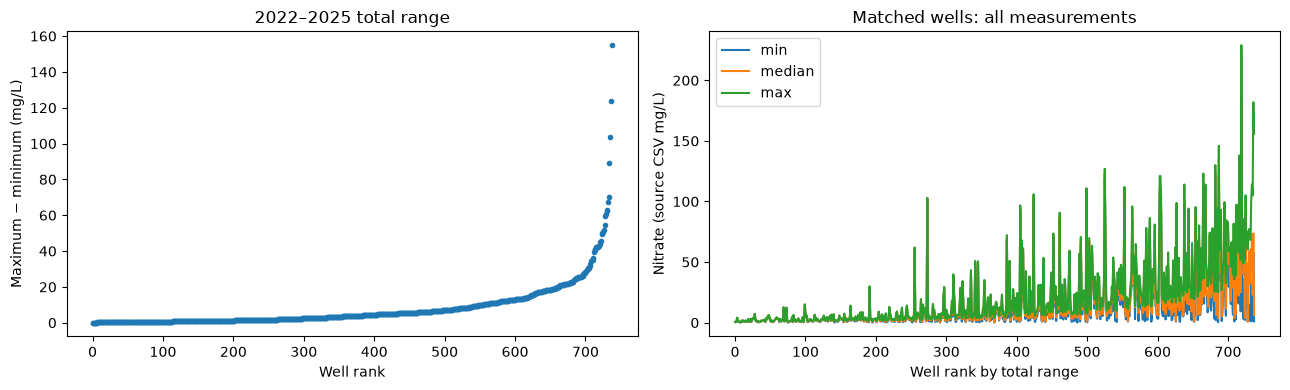

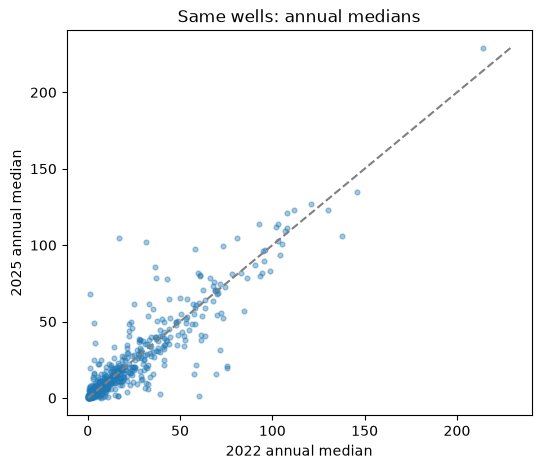

In [7]:
annual_means = annual_summary.pivot(index="gm_well_id", columns="year", values="mean").reindex(columns=years)
annual_medians = annual_summary.pivot(index="gm_well_id", columns="year", values="median").reindex(columns=years)
complete_means = annual_means.dropna()
complete_medians = annual_medians.loc[complete_means.index]
print(f"Well IDs measured in all four years: {len(complete_means)}")
display(complete_means)
display(complete_medians)
annual_changes = complete_medians.diff(axis=1).drop(columns=2022)
display(annual_changes.describe())

complete_data = groundwater_period[groundwater_period["gm_well_id"].isin(complete_means.index)]
matched_stats = complete_data.groupby("gm_well_id")["nitrate_mg_L"].agg(["min", "median", "max"])
matched_stats["range"] = matched_stats["max"] - matched_stats["min"]
matched_stats = matched_stats.sort_values("range")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(matched_stats["range"].to_numpy(), ".")
axes[0].set(xlabel="Well rank", ylabel="Maximum âˆ’ minimum (mg/L)", title="2022â€“2025 total range")
for statistic in ["min", "median", "max"]:
    axes[1].plot(matched_stats[statistic].to_numpy(), label=statistic)
axes[1].set(xlabel="Well rank by total range", ylabel="Nitrate (source CSV mg/L)", title="Matched wells: all measurements")
axes[1].legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(complete_medians[2022], complete_medians[2025], s=12, alpha=0.4)
limit = complete_medians[[2022, 2025]].max().max()
ax.plot([0, limit], [0, limit], color="gray", linestyle="--")
ax.set(xlabel="2022 annual median", ylabel="2025 annual median", title="Same wells: annual medians")
plt.show()


## Interpretation and next steps

Review sampling coverage and matched-well changes before choosing a target period. IQR flags and large ranges do not establish measurement errors. This notebook does not merge nearby wells, select one year, decluster locations, or split data for model evaluation. Derived tables stay in memory. The cleaned data's treatment of censored nitrate and combined analytes remains unchanged and needs separate scientific review.